# 05_02 — Particionamiento y shuffle en PySpark

**Proyecto:** Big Data — NYC Yellow Taxi + NOAA · **Fase:** 05 — Optimización y rendimiento  
**Dataset:** NYC Yellow Taxi, enero–diciembre de 2024 (41,169,720 registros originales).  
**Entorno objetivo:** Docker (Linux), Python 3.11, Spark/PySpark 4.1.3, Java 17.

> **Propósito:** investigar experimentalmente cómo Spark distribuye y redistribuye los datos; no asumir que más o menos particiones mejora el rendimiento.

**Contexto de comparación:** esta ejecución se realizó con `local[4]` y heap de 4 GiB, tras un error de memoria observado con mayor concurrencia. **No** es metodológicamente correcto comparar estos tiempos de forma causal con los de `05_01` ejecutados con `local[*]`. La referencia funcional sí conserva el mismo resultado.

**Continuidad con `05_01`:** conservaremos los mismos 12 Parquet, los mismos filtros y la consulta `rutas_top20`. El notebook anterior registró el stage de lectura con **12 tareas**, un shuffle de **6.5 MiB / 359,495 registros** y una lectura adaptativa de **200 → 6 particiones**. Estos valores son **observaciones previas**, no resultados de los experimentos nuevos.

**Cómo trabajar:** ejecuta en orden. Este notebook tiene *experimentos costosos*: procesan el año completo varias veces. Puedes usar `MODO = "exploracion"` para estudiar las tendencias y después `MODO = "final"` para cinco repeticiones por escenario. No se inventan tiempos de ejecución.

## 1. Preguntas de investigación

1. ¿Cuántas particiones intervienen al leer el Parquet y cómo se distribuyen los registros?
2. ¿Qué diferencia hay entre `repartition(n)` y `coalesce(n)` en el plan físico?
3. ¿Qué ocurre con el tiempo y el trabajo de Spark cuando modificamos `spark.sql.shuffle.partitions`?
4. ¿Qué efecto tiene **Adaptive Query Execution (AQE)** y cómo lo reconocemos en Spark UI?
5. ¿Qué configuración resulta más conveniente **para estas consultas, estos archivos y este equipo**, sin cambiar el resultado lógico?

**Protocolo de evidencia:** comparar medianas de una misma sesión, consultar planes físicos y verificar equivalencia funcional. Una diferencia pequeña podría ser ruido y necesitar otras repeticiones.

## 2. Fundamento teórico: partición, tarea, stage y shuffle

- **Partición:** división lógica de un DataFrame/RDD. Una tarea (*task*) trabaja sobre una partición de una etapa, aunque el número de tareas puede variar entre etapas.
- **Stage:** conjunto de tareas que pueden ejecutarse sin una dependencia de shuffle que las separe.
- **`Exchange`:** operador físico que puede redistribuir datos, normalmente mediante shuffle. No todo `Exchange` es necesariamente el cuello de botella.
- **`spark.sql.shuffle.partitions`:** cantidad **nominal** de particiones empleada en determinadas operaciones de shuffle SQL. No fija obligatoriamente el número final de tareas si AQE adapta el plan.
- **`coalesce(n)`:** cuando se usa para **reducir** particiones, normalmente evita un shuffle completo y puede disminuir el paralelismo.
- **`repartition(n)`:** solicita un nuevo particionamiento y por regla general introduce una redistribución completa (*shuffle*). Se utiliza tanto para aumentar como para disminuir particiones.
- **AQE:** permite cambiar el plan físico durante la ejecución; entre otras cosas, puede fusionar particiones de shuffle pequeñas.

**Modelo conceptual — NO una ley de tiempos:**

$$
T(p) \approx T_{\mathrm{fijo}} + T_{\mathrm{trabajo}}(p) + T_{\mathrm{shuffle}}(p) + T_{\mathrm{planificación}}(p).
$$

Tener más particiones puede mejorar la concurrencia hasta cierto punto, pero también aumenta los costos de coordinación. Tener menos puede ahorrar tareas, pero perder paralelismo. En un equipo con ~12 CPU lógicas, **no existe un número universalmente óptimo**.

**Importante:** los **12 archivos** no implican necesariamente **12 particiones**. El número depende de tamaños, configuración, estrategia de lectura y plan físico.

## 3. Importaciones y localización del repositorio

Usaremos solo Python estándar + PySpark; no se requiere `pandas` para el benchmarking. El repositorio debe estar montado dentro de Docker y contener `data/` y `README.md`.

In [1]:
from __future__ import annotations

import json
import math
import os
import platform
import statistics
import sys
import time
from datetime import datetime, timedelta, timezone
from pathlib import Path
from typing import Callable

from pyspark.sql import DataFrame, SparkSession
from pyspark.sql import functions as F


def encontrar_raiz_proyecto(inicio: Path) -> Path:
    """Ubica el repositorio sin depender de una ruta local de Windows."""
    inicio = inicio.expanduser().resolve()
    for carpeta in (inicio, *inicio.parents):
        if (carpeta / "data").is_dir() and (carpeta / "README.md").is_file():
            return carpeta
    raise FileNotFoundError(
        "No encuentro README.md y data/. Abre el notebook desde el repositorio "
        "montado en Docker, o ajusta PROJECT_ROOT manualmente."
    )

PROJECT_ROOT = encontrar_raiz_proyecto(Path.cwd())
DATA_ROOT = PROJECT_ROOT / "data"
BENCHMARKS_ROOT = PROJECT_ROOT / "docs" / "benchmarks"
BENCHMARKS_ROOT.mkdir(parents=True, exist_ok=True)

print("Proyecto:", PROJECT_ROOT)
print("Python:", sys.executable)
print("Sistema:", platform.system(), platform.python_version())

Proyecto: /workspace
Python: /usr/local/bin/python3.11
Sistema: Linux 3.11.17


## 4. Iniciar Spark y fijar el contexto experimental

La sesión registrada en las salidas utiliza **`local[4]`**, un heap máximo comprobado de **4 GiB**, Spark 4.1.3 en **Linux/Docker**, zona horaria UTC y 200 particiones nominales de shuffle con AQE inicialmente activado.

Elegimos esta configuración tras un `java.lang.OutOfMemoryError: Java heap space` en un intento previo con mayor concurrencia. Reducir la concurrencia y configurar el heap **permitió completar los nuevos experimentos**, pero no demuestra por sí solo cuál de los dos cambios resolvió el fallo.

**Precaución:** `SparkSession.builder.getOrCreate()` puede reutilizar una sesión ya existente. La memoria del driver debe fijarse **antes de arrancar la JVM**; asignar `.config("spark.driver.memory", "4g")` a una sesión ya creada no modifica su heap. El límite efectivo se verificó aparte como 4 GiB.

Las configuraciones de AQE y shuffle se alteran **solo durante cada escenario** y después se restauran. No llamamos a `spark.stop()`, de modo que Spark UI permanece disponible mientras viva la aplicación. Para ejecutar de nuevo el notebook tras cambiar recursos, reinicia el kernel o el contenedor como corresponda.

In [2]:
spark = (
    SparkSession.builder
    .appName("05_02_particionamiento_shuffle")
    .master("local[4]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "200")
    .config("spark.sql.adaptive.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

# Debe coincidir con el criterio temporal de nuestro baseline.
spark.conf.set("spark.sql.session.timeZone", "Etc/UTC")

CONFIG_INICIAL = {
    "spark.sql.shuffle.partitions": spark.conf.get("spark.sql.shuffle.partitions"),
    "spark.sql.adaptive.enabled": spark.conf.get("spark.sql.adaptive.enabled"),
    "spark.sql.adaptive.coalescePartitions.enabled": spark.conf.get(
        "spark.sql.adaptive.coalescePartitions.enabled"
    ),
}

ENTORNO = {
    "spark_version": spark.version,
    "application_id": spark.sparkContext.applicationId,
    "app_name": spark.sparkContext.appName,
    "master": spark.sparkContext.master,
    "parallelism": spark.sparkContext.defaultParallelism,
    "cpu_logicas": os.cpu_count(),
    "sistema": platform.system(),
    "python": platform.python_version(),
    "ui": spark.sparkContext.uiWebUrl,
    "timezone": spark.conf.get("spark.sql.session.timeZone"),
    "configuracion_inicial": CONFIG_INICIAL,
}
for k, v in ENTORNO.items():
    print(f"{k:26s}: {v}")

if platform.system() != "Linux":
    print("ADVERTENCIA: ejecución fuera de Linux/Docker; no compares tiempos con su baseline Linux.")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/16 01:09:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


spark_version             : 4.1.3
application_id            : local-1792112954403
app_name                  : 05_02_particionamiento_shuffle
master                    : local[4]
parallelism               : 4
cpu_logicas               : 12
sistema                   : Linux
python                    : 3.11.17
ui                        : http://8e7968dee514:4040
timezone                  : Etc/UTC
configuracion_inicial     : {'spark.sql.shuffle.partitions': '200', 'spark.sql.adaptive.enabled': 'true', 'spark.sql.adaptive.coalescePartitions.enabled': 'true'}


## 5. Seleccionar los 12 Parquet y validar las rutas

El período completo de 2024 es nuestro conjunto principal. La búsqueda exige **un archivo único por mes**; si existen duplicados se debe indicar una ruta explícita en lugar de seleccionar uno arbitrariamente. Las operaciones de filtrado son idénticas a `05_01`.

In [3]:
MESES = [f"2024-{mes:02d}" for mes in range(1, 13)]
RUTAS_EXPLICITAS: dict[str, str] = {}


def siguiente_mes(fecha: datetime) -> datetime:
    """Primer día del mes siguiente, sin depender de librerías externas."""
    return (fecha.replace(day=28) + timedelta(days=4)).replace(day=1)


def localizar_parquet(mes: str) -> Path:
    if mes in RUTAS_EXPLICITAS:
        ruta = Path(RUTAS_EXPLICITAS[mes]).expanduser().resolve()
        if not ruta.is_file():
            raise FileNotFoundError(f"No existe el archivo de {mes}: {ruta}")
        return ruta

    rutas = sorted(DATA_ROOT.rglob(f"yellow_tripdata_{mes}.parquet"))
    if len(rutas) != 1:
        raise RuntimeError(
            f"Se esperaba un único Parquet para {mes}; se encontraron {len(rutas)}. "
            f"Configura RUTAS_EXPLICITAS. Coincidencias: {rutas}"
        )
    return rutas[0]


def ruta_relativa(ruta: Path) -> str:
    try:
        return str(ruta.relative_to(PROJECT_ROOT))
    except ValueError:
        return ruta.name

MESES = sorted(set(MESES))
ARCHIVOS = [localizar_parquet(mes) for mes in MESES]
FECHA_INICIO = datetime.strptime(MESES[0], "%Y-%m")
FECHA_FIN_EXCLUSIVA = siguiente_mes(datetime.strptime(MESES[-1], "%Y-%m"))
TAMANO_MIB = sum(r.stat().st_size for r in ARCHIVOS) / (1024 ** 2)

print(f"Archivos mensuales: {len(ARCHIVOS)}")
print(f"Tamaño físico: {TAMANO_MIB:,.3f} MiB")
print("Intervalo:", FECHA_INICIO, "→", FECHA_FIN_EXCLUSIVA, "(exclusivo)")
print("Primer archivo:", ruta_relativa(ARCHIVOS[0]))

Archivos mensuales: 12
Tamaño físico: 660.898 MiB
Intervalo: 2024-01-01 00:00:00 → 2025-01-01 00:00:00 (exclusivo)
Primer archivo: data/raw/taxi/year=2024/yellow_tripdata_2024-01.parquet


## 6. Consulta fija: rutas más frecuentes

Utilizaremos **exactamente la lógica** de `rutas_top20` del notebook anterior, porque contiene un `Exchange` que podemos investigar en Spark UI.

1. Seleccionamos cinco columnas y aplicamos los mismos filtros.
2. Agrupamos por zona de origen y de destino.
3. Calculamos cantidad de viajes e ingreso total.
4. Ordenamos con desempate determinista y seleccionamos 20 rutas.

**Advertencia:** aplicar `repartition()` antes de la agregación puede trasladar muchos registros y **empeorar** el rendimiento. Lo ensayaremos como experimento controlado, no como una optimización garantizada.

In [4]:
COLUMNAS_REQUERIDAS = {
    "tpep_pickup_datetime", "PULocationID", "DOLocationID",
    "trip_distance", "total_amount",
}


def leer_taxi() -> DataFrame:
    """Lectura perezosa de los mismos archivos que el baseline 05_01."""
    return spark.read.parquet(*(str(p) for p in ARCHIVOS))


def viajes_filtrados() -> DataFrame:
    """Mismos filtros, tipos y columnas que el baseline anual."""
    df = leer_taxi().select(
        "tpep_pickup_datetime", "PULocationID", "DOLocationID",
        "trip_distance", "total_amount",
    )
    return df.filter(
        (F.col("tpep_pickup_datetime") >= F.lit(FECHA_INICIO))
        & (F.col("tpep_pickup_datetime") < F.lit(FECHA_FIN_EXCLUSIVA))
        & F.col("PULocationID").isNotNull()
        & F.col("DOLocationID").isNotNull()
        & (F.col("trip_distance") > 0)
        & (F.col("trip_distance") < 100)
        & (F.col("total_amount") >= 0)
    )


def rutas_top20(df_entrada: DataFrame) -> DataFrame:
    """Consulta fija: recibe una entrada para poder cambiar solo el particionamiento."""
    return (
        df_entrada.groupBy("PULocationID", "DOLocationID")
        .agg(
            F.count("*").alias("num_viajes"),
            F.sum("total_amount").alias("ingreso_total"),
        )
        .orderBy(
            F.desc("num_viajes"),
            F.asc("PULocationID"),
            F.asc("DOLocationID"),
        )
        .limit(20)
    )


def consulta_original() -> DataFrame:
    return rutas_top20(viajes_filtrados())

faltantes = sorted(COLUMNAS_REQUERIDAS - set(leer_taxi().columns))
if faltantes:
    raise ValueError(f"Faltan columnas en los Parquet: {faltantes}")

print("Columnas de entrada correctas:", sorted(COLUMNAS_REQUERIDAS))

Columnas de entrada correctas: ['DOLocationID', 'PULocationID', 'total_amount', 'tpep_pickup_datetime', 'trip_distance']


## 7. Corrección funcional: misma salida que `05_01`

El notebook previo puede haber guardado:

`docs/benchmarks/05_01_referencia_logica_2024-01_a_2024-12.json`

Lo usaremos para comparar **claves, conteos y sumas**. Para sumas en punto flotante, el orden de reducción paralelo puede cambiar los últimos decimales; por eso se utiliza `math.isclose` con tolerancias pequeñas. Si el archivo no existe, construiremos una **referencia temporal en esta sesión** y lo indicaremos explícitamente; no sobrescribiremos ningún archivo de `05_01`.

**Nunca aceptaremos una mejora de tiempo si cambian las 20 rutas, sus conteos o sus sumas fuera de tolerancia.**

In [5]:
ETIQUETA_PERIODO = (
    MESES[0] if len(MESES) == 1 else f"{MESES[0]}_a_{MESES[-1]}"
)
RUTA_REFERENCIA = (
    BENCHMARKS_ROOT / f"05_01_referencia_logica_{ETIQUETA_PERIODO}.json"
)


def normalizar_salida(df: DataFrame) -> list[dict]:
    """Recolecta ÚNICAMENTE una salida pequeña (20 rutas)."""
    filas = [fila.asDict(recursive=True) for fila in df.collect()]
    return sorted(filas, key=lambda f: (f["PULocationID"], f["DOLocationID"]))


if RUTA_REFERENCIA.is_file():
    with RUTA_REFERENCIA.open("r", encoding="utf-8") as f:
        doc_referencia = json.load(f)
    if doc_referencia.get("periodo") != MESES:
        raise ValueError("La referencia 05_01 no corresponde a los mismos meses.")
    referencia_rutas = sorted(
        doc_referencia["resultados"]["rutas_top20"],
        key=lambda f: (f["PULocationID"], f["DOLocationID"]),
    )
    FUENTE_REFERENCIA = ruta_relativa(RUTA_REFERENCIA)
    print("Referencia 05_01 encontrada:", FUENTE_REFERENCIA)
else:
    print("ATENCIÓN: falta referencia de 05_01; calculamos una TEMPORAL en esta sesión.")
    referencia_rutas = normalizar_salida(consulta_original())
    FUENTE_REFERENCIA = "temporal_en_sesion"


def comprobar_rutas(salida: list[dict]) -> None:
    """Verifica claves y conteos exactos, ingreso_total casi igual."""
    actual = sorted(
        salida,
        key=lambda f: (f["PULocationID"], f["DOLocationID"]),
    )
    if len(actual) != len(referencia_rutas):
        raise AssertionError("La cantidad de rutas cambió.")
    for esperado, observado in zip(referencia_rutas, actual):
        for clave in ("PULocationID", "DOLocationID", "num_viajes"):
            if esperado[clave] != observado[clave]:
                raise AssertionError(
                    f"La columna {clave} cambió: {esperado[clave]} vs {observado[clave]}"
                )
        if not math.isclose(
            float(esperado["ingreso_total"]),
            float(observado["ingreso_total"]),
            rel_tol=1e-8,
            abs_tol=1e-5,
        ):
            raise AssertionError("La suma ingreso_total cambió fuera de tolerancia.")

print("Filas de referencia:", len(referencia_rutas))
assert len(referencia_rutas) == 20, "Se esperaban 20 rutas en el escenario de referencia."

Referencia 05_01 encontrada: docs/benchmarks/05_01_referencia_logica_2024-01_a_2024-12.json
Filas de referencia: 20


## 8. Identificar particiones y distribución de los datos

Inspeccionaremos el paralelismo **antes** de la agregación. `rdd.getNumPartitions()` informa la cantidad prevista de particiones del DataFrame materializado como RDD; no es necesariamente igual a `spark.sql.shuffle.partitions`.

Luego, con `spark_partition_id()`, contaremos cuántas filas filtradas procesa cada partición. **Esta segunda parte recorre el dataset completo**: se ejecuta una vez y se mantiene fuera de los tiempos de los benchmarks.

Contrasta estos resultados con el *Stage 29* estudiado en `05_01` (12 tareas de lectura con duraciones de aproximadamente 4–5 s). La distribución observada puede variar según el ambiente y las opciones de lectura.

**Lectura de resultados registrados:** se observaron **6 particiones**, que procesaron **39,833,077 viajes válidos**. La partición más pequeña tiene **5,778,472** registros y la mayor **7,324,636**; la razón máximo/mínimo es **1.268**. En cantidad de filas no se advierte un desequilibrio extremo, aunque la duración por tarea y los bytes realmente procesados son necesarios para evaluar *skew* con mayor rigor.

La cantidad de particiones iniciales depende de la planificación de archivos y de la configuración de Spark; no se deduce exclusivamente de usar `local[4]` ni del tamaño de 660.898 MiB en Parquet.

In [6]:
df_lectura = viajes_filtrados()
print("Particiones de lectura planificadas:", df_lectura.rdd.getNumPartitions())
print("Paralelismo por defecto:", spark.sparkContext.defaultParallelism)

# Acciones sobre el año completo: activar/desactivar para controlar el costo de análisis.
INSPECCIONAR_DISTRIBUCION = True

if INSPECCIONAR_DISTRIBUCION:
    por_particion = (
        viajes_filtrados()
        .withColumn("_particion_id", F.spark_partition_id())
        .groupBy("_particion_id")
        .agg(F.count("*").alias("registros"))
        .orderBy("_particion_id")
        .collect()
    )
    cantidades = [int(f["registros"]) for f in por_particion]
    for fila in por_particion:
        print(f"Partición {fila['_particion_id']:>3}: {fila['registros']:>12,} registros")
    print("Particiones no vacías:", len(cantidades))
    print("Registros filtrados:", f"{sum(cantidades):,}")
    print("Mín / mediana / máx:",
          f"{min(cantidades):,} / {statistics.median(cantidades):,.0f} / {max(cantidades):,}")
    print("Razón máximo/mínimo:", round(max(cantidades) / min(cantidades), 3))
else:
    por_particion = []
    print("Inspección de distribución omitida (INSPECCIONAR_DISTRIBUCION=False).")

Particiones de lectura planificadas: 6
Paralelismo por defecto: 4


[Stage 3:=================================================>         (5 + 1) / 6]

Partición   0:    7,324,636 registros
Partición   1:    7,027,827 registros
Partición   2:    6,976,704 registros
Partición   3:    6,870,178 registros
Partición   4:    5,855,260 registros
Partición   5:    5,778,472 registros
Particiones no vacías: 6
Registros filtrados: 39,833,077
Mín / mediana / máx: 5,778,472 / 6,923,441 / 7,324,636
Razón máximo/mínimo: 1.268


## 9. `coalesce()` frente a `repartition()`

Con **6 particiones de entrada** observadas, `coalesce(6)` no habría reducido el paralelismo. Por ello esta ejecución emplea:

- **`sin_cambio` (6):** consulta de referencia sin redistribución explícita.
- **`coalesce_3` (3):** intenta reducir a 3 particiones, sin añadir un shuffle completo; cada tarea puede procesar más datos.
- **`repartition_12` (12):** redistribuye mediante `Exchange RoundRobinPartitioning(12)`.
- **`repartition_24` (24):** redistribuye mediante `Exchange RoundRobinPartitioning(24)`.

Los planes `explain(mode="simple")` permiten identificar `Coalesce` y `Exchange` **sin ejecutar la consulta completa**. Aunque el recuento con `.rdd.getNumPartitions()` puede parecer una inspección inocua, en este caso activó stages al materializar el plan de `repartition`; para evitarlo, la celda siguiente muestra el objetivo de las transformaciones sin obligar a ejecutar un shuffle.

**Nota sobre las salidas preservadas:** los stages 14 y 16 impresos en esta celda proceden de la ejecución original antes de este ajuste documental. Las salidas y mediciones se mantienen como evidencia histórica; al volver a ejecutar la versión corregida ya no deberían generarse esos stages por esta inspección.

In [7]:
def entrada_particionada(modo: str) -> DataFrame:
    df = viajes_filtrados()

    if modo == "sin_cambio":
        return df

    if modo == "coalesce_3":
        return df.coalesce(3)

    if modo == "repartition_12":
        return df.repartition(12)

    if modo == "repartition_24":
        return df.repartition(24)

    raise ValueError(
        f"Modo de particionamiento no reconocido: {modo}"
    )


def consulta_particionada(modo: str) -> DataFrame:
    return rutas_top20(entrada_particionada(modo))


# Solo informamos las particiones de lectura ya observadas y los objetivos
# declarados de cada transformación. Evita .rdd.getNumPartitions() sobre
# repartition, que puede disparar un stage (shuffle) incluso antes del benchmark.
particiones_lectura = len(por_particion) if por_particion else df_lectura.rdd.getNumPartitions()
particiones_previstas = {
    "sin_cambio": particiones_lectura,
    "coalesce_3": min(3, particiones_lectura),
    "repartition_12": 12,
    "repartition_24": 24,
}
for modo, cantidad in particiones_previstas.items():
    print(f"{modo:17s}: {cantidad} particiones (entrada/objetivo)")

print("\nPlan SIMPLE de coalesce(3):")
consulta_particionada("coalesce_3").explain(mode="simple")
print("\nPlan SIMPLE de repartition(24):")
consulta_particionada("repartition_24").explain(mode="simple")


sin_cambio       : 6 particiones
coalesce_3       : 3 particiones


[Stage 14:======================================>                   (4 + 2) / 6]

repartition_12   : 12 particiones


[Stage 16:======================================>                   (4 + 2) / 6]

repartition_24   : 24 particiones

Plan SIMPLE de coalesce(3):


== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- TakeOrderedAndProject(limit=20, orderBy=[num_viajes#170L DESC NULLS LAST,PULocationID#157 ASC NULLS FIRST,DOLocationID#158 ASC NULLS FIRST], output=[PULocationID#157,DOLocationID#158,num_viajes#170L,ingreso_total#171])
   +- HashAggregate(keys=[PULocationID#157, DOLocationID#158], functions=[count(1), sum(total_amount#166)])
      +- Exchange hashpartitioning(PULocationID#157, DOLocationID#158, 200), ENSURE_REQUIREMENTS, [plan_id=251]
         +- HashAggregate(keys=[PULocationID#157, DOLocationID#158], functions=[partial_count(1), partial_sum(total_amount#166)])
            +- Coalesce 3
               +- Project [PULocationID#157, DOLocationID#158, total_amount#166]
                  +- Filter (((((((((isnotnull(tpep_pickup_datetime#151) AND isnotnull(trip_distance#154)) AND isnotnull(total_amount#166)) AND (tpep_pickup_datetime#151 >= 2024-01-01 00:00:00)) AND (tpep_pickup_datetime#151 < 2025-01-01 00:00:00)) AND isnotnull(PU

## 10. Protocolo de benchmarking

- Mediremos el tiempo **de construir la consulta y ejecutar `collect()`**, igual que en `05_01`.
- La salida tiene solo 20 filas: no descargaremos los 41 millones al driver.
- **Una ronda de calentamiento por escenario** y luego mediciones intercaladas para reducir parcialmente el efecto del orden.
- `spark.catalog.clearCache()` evita reutilizar cachés explícitas de Spark, pero **no limpia** la caché del sistema operativo.
- La comprobación de resultados se hace **fuera del cronómetro**. El costo de lectura desde disco, planificación y ejecución dentro de `collect()` sí queda incluido.
- Para comparaciones finales usa **cinco mediciones**; la exploración rápida utiliza tres. No consideres mejoras de pocos puntos porcentuales concluyentes si son comparables con la dispersión de los tiempos.

**Configuraciones A:** AQE = `true` y shuffle = `200`, salvo que debamos restaurar al concluir.  
**Configuraciones B:** combinaremos AQE habilitado/deshabilitado con 12 y 200 particiones de shuffle.

Los datos y filtros permanecen iguales. Como los casos se ejecutan en la misma sesión, las comparaciones **dentro de `05_02`** son más defendibles que comparar directamente con una ejecución anterior de `05_01`.

In [8]:
MODO = "exploracion"  # "exploracion": 3 repeticiones; "final": 5.
CALENTAMIENTOS = 1
REPETICIONES = {"exploracion": 3, "final": 5}[MODO]

# Diccionario de consultas ejecutadas para volver a inspeccionar sus planes físicos.
PLANES_EJECUTADOS: dict[tuple[str, str], DataFrame] = {}


def resumen_muestra(tiempos: list[float]) -> dict:
    return {
        "tiempos_s": [round(float(t), 6) for t in tiempos],
        "mediana_s": statistics.median(tiempos),
        "media_s": statistics.mean(tiempos),
        "desviacion_s": statistics.stdev(tiempos) if len(tiempos) > 1 else 0.0,
        "minimo_s": min(tiempos),
        "maximo_s": max(tiempos),
    }


def realizar_experimento(
    grupo: str,
    escenarios: list[dict],
    calentamientos: int = CALENTAMIENTOS,
    repeticiones: int = REPETICIONES,
) -> list[dict]:
    """
    Ejecuta escenarios con calentamiento e intercala los órdenes de medición.

    Estructura de cada escenario:
      nombre, preparar() [configuración fuera de tiempo], construir() y metadatos.
    """
    if not escenarios or repeticiones < 2 or calentamientos < 0:
        raise ValueError("Se requieren escenarios, >=2 repeticiones y calentamientos >=0")

    sc = spark.sparkContext
    mediciones = {esc["nombre"]: [] for esc in escenarios}

    def una_ejecucion(esc: dict, etiqueta: str) -> None:
        # Cambiar configuraciones ANTES de construir el DataFrame.
        esc["preparar"]()
        spark.catalog.clearCache()
        sc.setJobGroup(
            f"05_02_{grupo}_{esc['nombre']}_{etiqueta}",
            f"05_02 {grupo}: {esc['nombre']} ({etiqueta})",
            interruptOnCancel=True,
        )
        try:
            inicio = time.perf_counter()
            df = esc["construir"]()
            salida = [f.asDict(recursive=True) for f in df.collect()]
            duracion = time.perf_counter() - inicio
        finally:
            # Limpiar las propiedades locales del grupo de trabajo.
            sc.setLocalProperty("spark.jobGroup.id", None)
            sc.setLocalProperty("spark.job.description", None)
            sc.setLocalProperty("spark.job.interruptOnCancel", None)

        # Validar fuera de cronómetro: no aceptamos resultados incorrectos.
        comprobar_rutas(salida)
        PLANES_EJECUTADOS[(grupo, esc["nombre"])] = df
        print(f"{grupo:9s} / {esc['nombre']:19s} / {etiqueta:14s} "
              f"= {duracion:7.3f} s | validación OK")
        if etiqueta.startswith("medicion"):
            mediciones[esc["nombre"]].append(duracion)

    # Calentamos todos antes de registrar las mediciones.
    for indice in range(calentamientos):
        for esc in escenarios:
            una_ejecucion(esc, f"warmup_{indice+1}")

    # Intercalación circular del orden: mitiga, sin eliminar, la variación temporal.
    for ronda in range(repeticiones):
        orden = escenarios[ronda % len(escenarios):] + escenarios[:ronda % len(escenarios)]
        for esc in orden:
            una_ejecucion(esc, f"medicion_{ronda+1}")

    return [
        {
            "grupo": grupo,
            "nombre": esc["nombre"],
            "metadatos": esc["metadatos"],
            "calentamientos": calentamientos,
            "repeticiones": repeticiones,
            "filas_salida": len(referencia_rutas),
            **resumen_muestra(mediciones[esc["nombre"]]),
        }
        for esc in escenarios
    ]


def presentar_resultados(resultados: list[dict], nombre_referencia: str) -> None:
    tabla = {fila["nombre"]: fila for fila in resultados}
    mediana_ref = tabla[nombre_referencia]["mediana_s"]
    print(f"{'Escenario':20s} {'Mediana(s)':>11} {'Desv.(s)':>10} {'Mejora vs ref':>14}")
    print("-" * 61)
    for fila in sorted(resultados, key=lambda r: r["mediana_s"]):
        cambio_pct = 100 * (mediana_ref - fila["mediana_s"]) / mediana_ref
        print(f"{fila['nombre']:20s} {fila['mediana_s']:11.3f} "
              f"{fila['desviacion_s']:10.3f} {cambio_pct:13.1f}%")
    print("Mejora positiva = menor tiempo que la referencia de ESTE grupo.")

print("Modo:", MODO, "| calentamientos:", CALENTAMIENTOS,
      "| repeticiones:", REPETICIONES)

Modo: exploracion | calentamientos: 1 | repeticiones: 3


## 11. Experimento A — Particionamiento explícito del DataFrame

Fijamos AQE activado y el shuffle nominal en 200 para comparar únicamente la transformación anterior a `groupBy`.

**Interpretación esperada (hipótesis, no respuesta):** `coalesce(3)` podría reducir el paralelismo de 6 a 3 tareas; `repartition(24)` podría añadir un shuffle de millones de filas. Comprobaremos el plan físico **y** el tiempo. Una hipótesis puede quedar refutada por las mediciones.

**Evidencia observada:** ambos `repartition` introdujeron un `Exchange RoundRobinPartitioning` adicional **antes** del `Exchange hashpartitioning` que la agregación requería de todos modos. La consulta original ya tenía una distribución de entrada razonablemente equilibrada en número de filas, por lo que no era evidente que un shuffle extra aportara beneficios.

In [9]:
ESCENARIOS_A = [
    {
        "nombre": modo,
        "preparar": lambda: (
            spark.conf.set("spark.sql.adaptive.enabled", "true"),
            spark.conf.set("spark.sql.adaptive.coalescePartitions.enabled", "true"),
            spark.conf.set("spark.sql.shuffle.partitions", "200"),
        ),
        "construir": (lambda m=modo: consulta_particionada(m)),
        "metadatos": {
            "transformacion": modo,
            "aqe": True,
            "shuffle_partitions": 200,
        },
    }
    for modo in ("sin_cambio", "coalesce_3", "repartition_12", "repartition_24")
]

try:
    RESULTADOS_A = realizar_experimento("particion", ESCENARIOS_A)
finally:
    for clave, valor in CONFIG_INICIAL.items():
        spark.conf.set(clave, valor)

print("\nRESULTADOS DEL EXPERIMENTO A")
presentar_resultados(RESULTADOS_A, "sin_cambio")

particion / sin_cambio          / warmup_1       =   3.268 s | validación OK


particion / coalesce_3          / warmup_1       =   4.833 s | validación OK


particion / repartition_12      / warmup_1       =  15.982 s | validación OK


particion / repartition_24      / warmup_1       =  16.757 s | validación OK


particion / sin_cambio          / medicion_1     =   2.678 s | validación OK


...

particion / repartition_12      / medicion_3     =  15.899 s | validación OK


particion / repartition_24      / medicion_3     =  15.393 s | validación OK


particion / sin_cambio          / medicion_3     =   2.400 s | validación OK


[Stage 104:======================================>                  (2 + 1) / 3]

particion / coalesce_3          / medicion_3     =   2.830 s | validación OK

RESULTADOS DEL EXPERIMENTO A
Escenario             Mediana(s)   Desv.(s)  Mejora vs ref
-------------------------------------------------------------
sin_cambio                 2.400      0.161           0.0%
coalesce_3                 2.927      0.062         -22.0%
repartition_24            15.417      0.482        -542.3%
repartition_12            15.899      0.295        -562.4%
Mejora positiva = menor tiempo que la referencia de ESTE grupo.


### Resultado del Experimento A — Interpretación inmediata

El control `sin_cambio` alcanzó **2.400 s** de mediana. Reducir las particiones de 6 a 3 mediante `coalesce(3)` elevó la mediana a **2.927 s** (**+22.0 %**). Introducir `repartition(12)` y `repartition(24)` la elevó a **15.899 s** (**+562.4 %**) y **15.417 s** (**+542.3 %**), respectivamente.

El plan muestra la causa estructural principal que debemos investigar: `repartition()` añade un **shuffle completo** antes de la agregación, mientras que el `groupBy` mantiene su propio `Exchange`. La redistribución adicional es costosa en esta consulta; la correlación con el tiempo medido no constituye un perfil detallado de CPU/I/O sin Spark UI.

**Importante:** estas cifras pertenecen a la ejecución **actual** del notebook; no deben reemplazarse por resultados de corridas anteriores.

## 12. Experimento B — Número nominal de particiones y AQE

Ahora **no** aplicamos ni `coalesce` ni `repartition` a los datos de entrada: usamos exactamente `consulta_original()`.

Comparamos cuatro escenarios:

| Escenario | `spark.sql.shuffle.partitions` | AQE |
|---|---:|---|
| `12_sin_AQE` | 12 | Desactivado |
| `200_sin_AQE` | 200 | Desactivado |
| `12_con_AQE` | 12 | Activado |
| `200_con_AQE` | 200 | Activado |

El resultado esperado siempre son **las mismas 20 rutas**. Los planes podrán variar. En particular, con AQE activado las particiones leídas después del shuffle pueden fusionarse y no coincidir con el valor nominal.

**Pregunta clave:** si Spark fusiona 200 particiones en 6, ¿es razonable concluir que `spark.sql.shuffle.partitions=6` siempre será más rápido? **No**: el valor inicial interviene antes de la adaptación y puede influir en la distribución y en los costos de las tareas.

**Interpretación de la ejecución registrada:** los resultados muestran que 12 y 200 particiones nominales **con AQE** tienen medianas muy próximas (2.415 s y 2.407 s). Sin AQE, 200 particiones resultó más lento (2.662 s) que 12 (2.335 s); este patrón es compatible con mayor sobrecarga de coordinación/tareas pequeñas, pero la causa exacta exigiría contrastar los stages en Spark UI.

In [10]:
def configurar_shuffle(particiones: int, aqe: bool) -> None:
    """Modifica solo las opciones del experimento B antes de definir la consulta."""
    spark.conf.set("spark.sql.shuffle.partitions", str(particiones))
    spark.conf.set("spark.sql.adaptive.enabled", str(aqe).lower())
    spark.conf.set("spark.sql.adaptive.coalescePartitions.enabled", "true")


ESCENARIOS_B = []
for n, aqe in ((12, False), (200, False), (12, True), (200, True)):
    nombre = f"{n}_{'con' if aqe else 'sin'}_AQE"
    ESCENARIOS_B.append({
        "nombre": nombre,
        "preparar": (lambda p=n, a=aqe: configurar_shuffle(p, a)),
        "construir": consulta_original,
        "metadatos": {
            "transformacion": "sin_cambio",
            "aqe": aqe,
            "shuffle_partitions": n,
        },
    })

try:
    RESULTADOS_B = realizar_experimento("shuffle", ESCENARIOS_B)
finally:
    for clave, valor in CONFIG_INICIAL.items():
        spark.conf.set(clave, valor)

print("\nRESULTADOS DEL EXPERIMENTO B")
presentar_resultados(RESULTADOS_B, "200_con_AQE")

shuffle   / 12_sin_AQE          / warmup_1       =   2.412 s | validación OK


shuffle   / 200_sin_AQE         / warmup_1       =   2.898 s | validación OK


shuffle   / 12_con_AQE          / warmup_1       =   2.578 s | validación OK


shuffle   / 200_con_AQE         / warmup_1       =   2.452 s | validación OK


shuffle   / 12_sin_AQE          / medicion_1     =   2.473 s | validación OK


...

shuffle   / 12_con_AQE          / medicion_3     =   2.415 s | validación OK


shuffle   / 200_con_AQE         / medicion_3     =   2.385 s | validación OK


shuffle   / 12_sin_AQE          / medicion_3     =   2.308 s | validación OK


[Stage 161:======================================>                  (4 + 2) / 6]

shuffle   / 200_sin_AQE         / medicion_3     =   2.591 s | validación OK

RESULTADOS DEL EXPERIMENTO B
Escenario             Mediana(s)   Desv.(s)  Mejora vs ref
-------------------------------------------------------------
12_sin_AQE                 2.335      0.089           3.0%
200_con_AQE                2.407      0.225           0.0%
12_con_AQE                 2.415      0.035          -0.4%
200_sin_AQE                2.662      0.053         -10.6%
Mejora positiva = menor tiempo que la referencia de ESTE grupo.


### Resultado del Experimento B — Interpretación inmediata

Con AQE activado, **12 y 200** particiones nominales obtuvieron tiempos muy próximos (**2.415 s** y **2.407 s**). Sin AQE, la configuración de **200** particiones tardó **2.662 s**, frente a **2.335 s** con **12**.

Los resultados apoyan la hipótesis de que AQE reduce costos cuando una distribución nominal de 200 particiones resulta excesiva. Sin embargo, el mejor tiempo registrado (**2.335 s**, 12 sin AQE) **no es una recomendación universal**: hay tres repeticiones y la variabilidad importa. Los planes físicos confirman si AQE intervino; Spark UI ayuda a cuantificar número de tareas, shuffle y spill.

## 13. Revisar el plan **ejecutado** y Spark UI

No basta con modificar `spark.sql.shuffle.partitions`; necesitamos confirmar cómo Spark ejecutó cada caso.

1. Examina los planes finales de `200_sin_AQE` y `200_con_AQE`.
2. Busca `Exchange`, `AQEShuffleRead`, `AdaptiveSparkPlan`, `HashAggregate` y `TakeOrderedAndProject`.
3. En **Spark UI → Jobs**, identifica los grupos nombrados `05_02_shuffle_*`.
4. En **Stages**, registra número de tareas, shuffle read/write, spill y distribución de duraciones de tareas.
5. En **SQL / DataFrame**, inspecciona si AQE fusionó las particiones del shuffle. Que existan 200 particiones nominales **no** implica 200 tareas en el stage de lectura adaptativa.

**Distinción de métricas:** la suma de duraciones de las tareas puede superar el tiempo transcurrido de una consulta por paralelismo. Asimismo, `Duration` de la Spark UI puede incluir costos distintos del cronómetro Python utilizado aquí.

**Qué se confirmó en las salidas:** el plan sin AQE conserva un `Exchange` hacia la agregación final; con AQE aparece `AdaptiveSparkPlan` y una lectura `AQEShuffleRead` en el plan final. El texto del plan confirma la adaptación, pero no proporciona por sí solo todas las métricas de duración, spill y dispersión de tareas. Estas últimas deben verificarse en **Stages** de Spark UI.

In [11]:
for nombre in ("200_sin_AQE", "200_con_AQE", "12_con_AQE"):
    df_ejecutado = PLANES_EJECUTADOS.get(("shuffle", nombre))
    if df_ejecutado is not None:
        print("\n" + "=" * 74)
        print("PLAN FÍSICO —", nombre)
        print("=" * 74)
        # Mismo DataFrame que se ejecutó: relevante para observar AQE final.
        df_ejecutado.explain(mode="formatted")

print("\nSpark UI de esta sesión:", spark.sparkContext.uiWebUrl)
print("Si ejecutas en Docker, publica/redirige el puerto indicado antes de abrir localhost.")


PLAN FÍSICO — 200_sin_AQE
== Physical Plan ==
TakeOrderedAndProject (8)
+- * HashAggregate (7)
   +- Exchange (6)
      +- * HashAggregate (5)
         +- * Project (4)
            +- * Filter (3)
               +- * ColumnarToRow (2)
                  +- Scan parquet  (1)


(1) Scan parquet 
Output [5]: [tpep_pickup_datetime#1303, trip_distance#1306, PULocationID#1309, DOLocationID#1310, total_amount#1318]
Batched: true
Location: InMemoryFileIndex [file:/workspace/data/raw/taxi/year=2024/yellow_tripdata_2024-01.parquet, ... 11 entries]
PushedFilters: [IsNotNull(tpep_pickup_datetime), IsNotNull(trip_distance), IsNotNull(total_amount), GreaterThanOrEqual(tpep_pickup_datetime,2024-01-01T00:00), LessThan(tpep_pickup_datetime,2025-01-01T00:00), IsNotNull(PULocationID), IsNotNull(DOLocationID), GreaterThan(trip_distance,0.0), LessThan(trip_distance,100.0), GreaterThanOrEqual(total_amount,0.0)]
ReadSchema: struct<tpep_pickup_datetime:timestamp_ntz,trip_distance:double,PULocationID:int,DOLoc

## 14. Gráfico opcional y comparación con el baseline histórico

Los tiempos de `05_01` son una referencia histórica, **no la comparación principal**, porque las condiciones de sesión/OS/cache pueden cambiar. La comparación adecuada dentro de `05_02` usa `sin_cambio` (A) o `200_con_AQE` (B) como control contemporáneo.

Los **dos gráficos quedaron generados** en la ejecución adjunta. `matplotlib` forma parte del entorno Docker utilizado en esa corrida. Si se reproduce en otra imagen donde no esté instalado, la celda omite los gráficos y conserva las tablas anteriores.

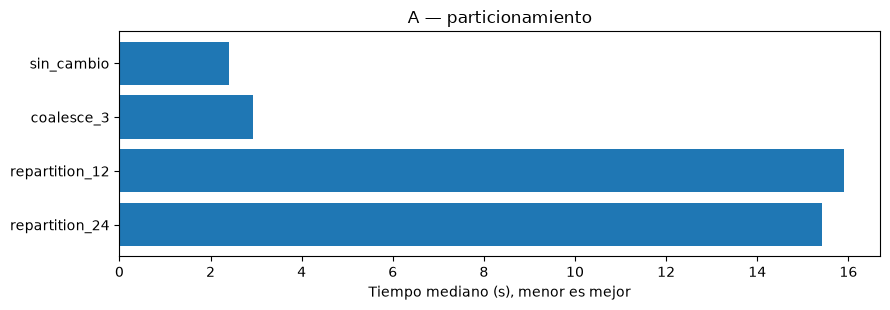

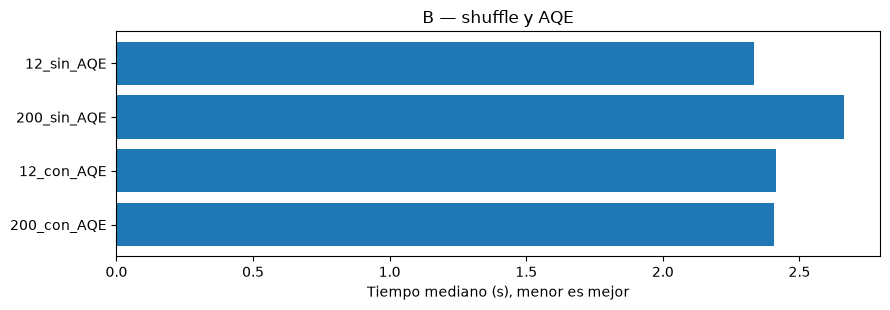

Baseline 05_01 histórico (no comparación causal): 2.296 s


In [12]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("matplotlib no está instalado; conserva las tablas impresas arriba.")
else:
    for nombre, datos in (("A — particionamiento", RESULTADOS_A),
                          ("B — shuffle y AQE", RESULTADOS_B)):
        etiquetas = [f["nombre"] for f in datos]
        medianas = [f["mediana_s"] for f in datos]
        fig, ax = plt.subplots(figsize=(9, max(3.0, 0.55 * len(datos) + 1)))
        ax.barh(etiquetas, medianas)
        ax.set_xlabel("Tiempo mediano (s), menor es mejor")
        ax.set_title(nombre)
        ax.invert_yaxis()
        fig.tight_layout()
        plt.show()

RUTA_BASELINE = BENCHMARKS_ROOT / f"05_01_baseline_{ETIQUETA_PERIODO}.json"
if RUTA_BASELINE.is_file():
    with RUTA_BASELINE.open("r", encoding="utf-8") as f:
        historico = json.load(f)
    ruta_historica = next(
        (x for x in historico.get("resultados", []) if x.get("workload") == "rutas_top20"),
        None,
    )
    if ruta_historica:
        print("Baseline 05_01 histórico (no comparación causal):",
              f"{ruta_historica['mediana_s']:.3f} s")
else:
    print("JSON histórico de 05_01 no disponible en docs/benchmarks/.")

## 15. Guardar resultados como evidencia reproducible

El reporte se almacena bajo `docs/benchmarks/` con una marca temporal para **no sobrescribir** ejecuciones anteriores.

Se guardan: archivos de entrada, configuraciones, ambiente, diseño experimental, tiempos individuales, estadísticos y ruta de referencia lógica. **No registramos como medida de los experimentos valores que solo vimos en las capturas del Stage 29 de `05_01`.**

**Alcance del JSON exportado:** la exportación de la sección 15 se efectuó **antes** de ejecutar el ejercicio adicional de 48 particiones de la sección 17. Por ello el reporte principal conserva los grupos **A y B**, pero **no** los resultados del ejercicio de 48 particiones. Este último se interpreta más abajo y se puede guardar en un JSON suplementario sin repetir los benchmarks.

In [13]:
MARCA_UTC = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUTA_SALIDA = (
    BENCHMARKS_ROOT / f"05_02_particionamiento_shuffle_{ETIQUETA_PERIODO}_{MARCA_UTC}.json"
)

REPORTE_05_02 = {
    "notebook": "05_02_particionamiento_shuffle",
    "fecha_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "modo": MODO,
    "periodo": MESES,
    "archivos": [ruta_relativa(p) for p in ARCHIVOS],
    "tamano_archivos_mib": round(TAMANO_MIB, 3),
    "ambiente": ENTORNO,
    "referencia_funcional": FUENTE_REFERENCIA,
    "condiciones": {
        "workload": "rutas_top20",
        "filtros": "idénticos a 05_01",
        "accion": "collect de 20 resultados",
        "cronometro": "Python time.perf_counter",
        "cache_spark": "clearCache antes de cada ejecución",
        "cache_sistema_operativo": "no controlado",
        "intercalado": "rotación de escenario por ronda",
        "calentamientos": CALENTAMIENTOS,
        "repeticiones": REPETICIONES,
    },
    "distribucion_entrada": {
        "medida": INSPECCIONAR_DISTRIBUCION,
        "registros_por_particion": [
            {"particion": int(r["_particion_id"]), "registros": int(r["registros"])}
            for r in por_particion
        ],
    },
    "resultados_a_particionamiento": RESULTADOS_A,
    "resultados_b_shuffle_aqe": RESULTADOS_B,
}

with RUTA_SALIDA.open("x", encoding="utf-8") as f:
    json.dump(REPORTE_05_02, f, ensure_ascii=False, indent=2, allow_nan=False)

print("Reporte guardado:", ruta_relativa(RUTA_SALIDA))
print("Para compartir resultados, adjunta este JSON y, si puedes, captura de Stages/SQL.")

Reporte guardado: docs/benchmarks/05_02_particionamiento_shuffle_2024-01_a_2024-12_20261016T011311Z.json
Para compartir resultados, adjunta este JSON y, si puedes, captura de Stages/SQL.


## 16. Interpretación de resultados y decisiones técnicas

Las respuestas siguientes se basan en **las salidas de esta versión ejecutada**, no en resultados de una corrida anterior del mismo notebook. Todas las medianas son de **tres mediciones** por escenario después de un calentamiento; los benchmarks son exploratorios.

### 1. ¿Cómo quedaron distribuidas las particiones de lectura?

Spark empleó **6 particiones de entrada**. Las filas válidas totales fueron **39,833,077**, distribuidas entre **5,778,472** y **7,324,636** por partición, con mediana **6,923,441** y relación máximo/mínimo **1.268**.

No observamos una asimetría extrema según el **número de filas**. Sin embargo, eso **no basta** para descartar *data skew*: también habría que comparar duración de tareas, bytes de entrada y tiempos máximos en Spark UI. La cantidad de particiones se explica por la planificación de lectura de Spark, no únicamente por los cuatro núcleos locales.

### 2. ¿Qué ocurrió al aplicar `repartition()`?

| Escenario | Mediana (s) | Desviación estándar (s) | Cambio de tiempo frente a `sin_cambio` |
|---|---:|---:|---:|
| `sin_cambio` | **2.400** | 0.161 | Referencia |
| `repartition_12` | 15.899 | 0.295 | **+562.4 %** |
| `repartition_24` | 15.417 | 0.482 | **+542.3 %** |

Los dos escenarios fueron mucho más lentos. Sus planes físicos incluyen un `Exchange RoundRobinPartitioning` adicional que redistribuye los registros **antes** de la agregación parcial, seguido por el `Exchange hashpartitioning` propio del `groupBy`. Para **esta consulta**, no se justifica el shuffle extra por una mejora observable de la distribución. No se puede extrapolar esta conclusión a todos los usos de `repartition()`.

### 3. ¿Qué sucedió con `coalesce(3)`?

| Escenario | Particiones previas a la agregación | Mediana (s) | Cambio frente a `sin_cambio` |
|---|---:|---:|---:|
| `sin_cambio` | 6 | **2.400** | Referencia |
| `coalesce_3` | 3 | 2.927 | **+22.0 %** |

`coalesce(3)` redujo el paralelismo de entrada sin un shuffle completo y empeoró el tiempo mediano. El resultado es coherente con tareas más grandes y menor concurrencia efectiva; no prueba de manera aislada que esa sea la única causa del aumento. `coalesce(6)` no habría sido útil para comparar una reducción, porque la lectura ya tenía seis particiones.

### 4. ¿Qué efecto tuvo cambiar 12 por 200 particiones de shuffle sin AQE?

| Escenario | Mediana (s) | Desviación estándar (s) |
|---|---:|---:|
| `12_sin_AQE` | **2.335** | 0.089 |
| `200_sin_AQE` | 2.662 | 0.053 |

El escenario con 200 particiones nominales tardó aproximadamente **14.0 % más** que el de 12. Esto es compatible con la sobrecarga de gestionar más particiones/tareas pequeñas, especialmente al redistribuir resultados agregados relativamente reducidos. Se deben revisar el **número real de tareas**, el tiempo de planificación y las métricas de shuffle en Spark UI para fundamentar esa explicación.

### 5. ¿Qué aportó AQE?

| Configuración | Mediana (s) | Desviación estándar (s) |
|---|---:|---:|
| `12_sin_AQE` | **2.335** | 0.089 |
| `200_con_AQE` | 2.407 | 0.225 |
| `12_con_AQE` | 2.415 | 0.035 |
| `200_sin_AQE` | 2.662 | 0.053 |

Con **200 particiones nominales**, AQE redujo la mediana de **2.662 s a 2.407 s** (aprox. **9.6 %** menos tiempo). El plan ejecutado con AQE contiene `AdaptiveSparkPlan` y `AQEShuffleRead`; la optimización permite reagrupar particiones después del shuffle cuando conviene.

En cambio, con **12 particiones**, la mediana fue 2.335 s sin AQE y 2.415 s con AQE. Esto **no demuestra** que desactivar AQE sea mejor en general: las diferencias son pequeñas y solo hubo tres mediciones. Tampoco se debe asumir que establecer directamente el número final de particiones adaptativas reproducirá siempre el comportamiento de AQE.

### 6. ¿Son robustas las diferencias?

Las brechas grandes del experimento A son claras en estas corridas: `repartition(12/24)` estuvo alrededor de **15–16 s** frente a **2.4 s** sin cambios. En cambio, la diferencia de **0.008 s** entre `200_con_AQE` y `12_con_AQE`, o la ventaja de **0.072 s** de `12_sin_AQE` frente a `200_con_AQE`, **no justifican declarar un ganador definitivo** con solo tres repeticiones y un sistema operativo con caché no controlada.

La dispersión fue especialmente relevante en `200_con_AQE` (desviación **0.225 s**). Para elegir una configuración de producción harían falta más corridas bajo la misma carga y, de ser posible, repetir el experimento en días o sesiones diferentes.

### 7. ¿Se mantuvo la equivalencia de resultados?

**Sí.** Todas las ejecuciones A y B finalizaron con `validación OK` frente al archivo de referencia `05_01_referencia_logica_2024-01_a_2024-12.json`. La comparación exige las mismas **20 rutas**, claves `(PULocationID, DOLocationID)` y conteos exactos; verifica `ingreso_total` con tolerancia numérica por posibles diferencias de redondeo en agregaciones distribuidas.

### Decisión técnica de esta fase

Para **este workload y este entorno** conviene **evitar `repartition()` previo al `groupBy` si no existe una necesidad concreta de redistribución**; tampoco se observó beneficio de reducir de 6 a 3 particiones con `coalesce()`. El efecto de AQE resulta favorable frente a 200 particiones fijas, pero no hemos encontrado evidencia suficiente para afirmar que **12 sin AQE** sea universalmente óptimo. La práctica recomendada es mantener un control contemporáneo y medir cada modificación.

**Alcance:** ejecución local en Docker Linux, Spark 4.1.3, `local[4]`, heap 4 GiB, los 12 Parquet de taxi 2024, datos filtrados y la consulta de rutas. No extrapolar los tiempos a un clúster ni comparar directamente con el baseline `05_01` de `local[*]`.

### Próxima fase

`05_03 — Optimización de joins`: comparar estrategias de combinación de datos de taxi y clima, distinguiendo costo de lectura, shuffle y planes adaptativos.

## 17. Ejercicio B — Modifica el experimento

**Objetivo:** investigar si un escenario intermedio de shuffle (por ejemplo, **48 particiones**) cambia nuestras conclusiones, sin introducir un nuevo criterio de filtrado.

El siguiente código **está listo para ejecutar** y valida los resultados frente a las mismas 20 rutas. **No contestamos de antemano las preguntas analíticas**; decide con tus mediciones y la Spark UI.

**Preguntas:** ¿mejora frente a 12 y 200? ¿Qué configuración de AQE produjo menos tareas reales? ¿Son suficientemente grandes las diferencias respecto a la desviación estándar?

In [15]:
# OPCIONAL: habilita esta celda cambiando a True cuando quieras extender el estudio.
EJECUTAR_EJERCICIO_B = True

if EJECUTAR_EJERCICIO_B:
    escenarios_extra = [
        {
            "nombre": f"48_{'con' if aqe else 'sin'}_AQE",
            "preparar": (lambda a=aqe: configurar_shuffle(48, a)),
            "construir": consulta_original,
            "metadatos": {
                "transformacion": "sin_cambio",
                "aqe": aqe,
                "shuffle_partitions": 48,
            },
        }
        for aqe in (False, True)
    ]
    try:
        RESULTADOS_EJERCICIO_B = realizar_experimento(
            "extra48", escenarios_extra,
            calentamientos=CALENTAMIENTOS,
            repeticiones=REPETICIONES,
        )
    finally:
        for clave, valor in CONFIG_INICIAL.items():
            spark.conf.set(clave, valor)
    presentar_resultados(RESULTADOS_EJERCICIO_B, "48_con_AQE")
    print("Compara las medianas con el grupo B, con precaución por ser bloques separados.")
else:
    print("Ejercicio B desactivado. Activa EJECUTAR_EJERCICIO_B para experimentar.")

extra48   / 48_sin_AQE          / warmup_1       =   2.650 s | validación OK


extra48   / 48_con_AQE          / warmup_1       =   2.461 s | validación OK


extra48   / 48_sin_AQE          / medicion_1     =   2.600 s | validación OK


extra48   / 48_con_AQE          / medicion_1     =   2.482 s | validación OK


extra48   / 48_con_AQE          / medicion_2     =   2.511 s | validación OK


extra48   / 48_sin_AQE          / medicion_2     =   2.499 s | validación OK


extra48   / 48_sin_AQE          / medicion_3     =   2.383 s | validación OK


[Stage 188:======================================>                  (4 + 2) / 6]

extra48   / 48_con_AQE          / medicion_3     =   2.331 s | validación OK
Escenario             Mediana(s)   Desv.(s)  Mejora vs ref
-------------------------------------------------------------
48_con_AQE                 2.482      0.097           0.0%
48_sin_AQE                 2.499      0.108          -0.7%
Mejora positiva = menor tiempo que la referencia de ESTE grupo.
Compara las medianas con el grupo B, con precaución por ser bloques separados.


### Resultado del ejercicio adicional — 48 particiones

El ejercicio también se ejecutó y **todas las mediciones mostraron `validación OK`**:

| Escenario | Mediana (s) | Desviación estándar (s) |
|---|---:|---:|
| `48_con_AQE` | **2.482** | 0.097 |
| `48_sin_AQE` | 2.499 | 0.108 |

La diferencia de **0.017 s** entre ambos escenarios es pequeña respecto a la dispersión. Por tanto, **48 particiones no mostró una ventaja clara** bajo este protocolo. Se midió en **un bloque posterior** al experimento B, por lo que su comparación con los escenarios de 12 y 200 es orientativa, no una prueba controlada definitiva.

**Trazabilidad:** el JSON original exportado en la sección 15 se creó *antes* de este ejercicio y **no incluye** las mediciones de 48 particiones. Puedes ejecutar la celda suplementaria de la sección siguiente para guardarlas sin recalcular Spark.

In [ ]:
# OPCIONAL — exportación del ejercicio de 48 particiones (sin recomputar Spark).
# Esta celda solo guarda RESULTADOS_EJERCICIO_B, calculado arriba.
if "RESULTADOS_EJERCICIO_B" in globals():
    marca_extra_utc = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    ruta_extra_48 = (
        BENCHMARKS_ROOT
        / f"05_02_extra48_{ETIQUETA_PERIODO}_{marca_extra_utc}.json"
    )
    reporte_extra_48 = {
        "notebook": "05_02_particionamiento_shuffle",
        "tipo": "ejercicio_suplementario",
        "fecha_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "periodo": MESES,
        "entorno": ENTORNO,
        "condiciones": {
            "workload": "rutas_top20",
            "modo": MODO,
            "calentamientos": CALENTAMIENTOS,
            "repeticiones": REPETICIONES,
            "comparabilidad": "bloque separado del experimento B",
        },
        "resultados_48_particiones": RESULTADOS_EJERCICIO_B,
    }
    with ruta_extra_48.open("x", encoding="utf-8") as f:
        json.dump(reporte_extra_48, f, ensure_ascii=False, indent=2, allow_nan=False)
    print("Reporte suplementario guardado:", ruta_relativa(ruta_extra_48))
else:
    print("No hay resultados del ejercicio B en memoria; no se creó un reporte adicional.")


## 18. Cierre del notebook

### Verificaciones del experimento entregado

- [x] Ejecutados los **12 meses de 2024** en Linux/Docker.
- [x] Medida la distribución inicial: **6 particiones**, **39,833,077** registros válidos.
- [x] Comparados los planes de `coalesce(3)` y `repartition(24)`.
- [x] Ejecutado el **Experimento A** con cuatro alternativas, calentamiento y tres mediciones por escenario.
- [x] Ejecutado el **Experimento B** con las cuatro combinaciones de AQE y shuffle.
- [x] Validada la equivalencia de las 20 rutas con la referencia lógica de `05_01`.
- [x] Generados ambos gráficos con Matplotlib.
- [x] Exportado el JSON principal a `docs/benchmarks/`.
- [x] Ejecutado el ejercicio suplementario de **48 particiones**, con validación correcta.
- [x] Documentadas las siete respuestas de interpretación y la decisión técnica.
- [ ] **Opcional:** inspeccionar en Spark UI las métricas de Stages de `05_02` (duración por tarea, shuffle, spill) para fundamentar más a fondo las causas del tiempo.
- [ ] **Opcional:** exportar el JSON suplementario del ejercicio de 48 particiones mediante la celda añadida, sin repetir consultas.

### Conclusión general

En esta carga de trabajo de agregación sobre taxis de 2024, **añadir una redistribución completa (`repartition`) empeoró considerablemente el rendimiento** y reducir el paralelismo de entrada con `coalesce(3)` tampoco aportó beneficios. AQE mostró utilidad para reducir el costo asociado a **200 particiones nominales**, pero las diferencias pequeñas entre configuraciones no permiten declarar una ganadora con tres mediciones. La optimización debe centrarse en **eliminar trabajo innecesario, preservar resultados y medir en condiciones controladas**.

**Reproducibilidad:** los outputs ejecutados se conservaron sin volver a correr Spark. La celda de inspección de particiones se corrigió para futuros usos; por eso sus salidas previas pueden mostrar stages que ya no se dispararían con el código actualizado. El reporte principal del ejercicio permanece sin modificaciones y el notebook **no altera Parquet originales ni el baseline `05_01`**.

**Siguiente notebook:** `05_03 — Optimización de joins` (taxis + NOAA).